### Simple  QnA Bot  Without Langchain - With Groq

In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
import os
apiKey = os.getenv("OPENAI_API_KEY")

In [3]:
from groq import Groq

client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{
        "role" : "user" ,
        "content":"Explain Me Gen  Ai"
    }],
 
    max_completion_tokens=1000,
   
)
# detail_Ans= completion.choices[0]
# detail_Ans
# here some  tokens  are used in the  reasoning and  while some are used in the Response  of Answer Generating
completion.choices[0].message.content


# 


'## What Is Generative AI?\n\n**Generative AI** (short for *generative artificial intelligence*) is a class of machine‑learning models that can **create new content**—text, images, audio, video, code, or even 3‑D designs—rather than just classifying or predicting existing data.  \n\nThink of it as a very sophisticated “creative assistant”: you give it a prompt or some input, and it produces something that didn’t exist before, but that looks or sounds like it could have been made by a human.\n\n---\n\n## How Does It Work? (A High‑Level View)\n\n| Step | What Happens | Why It Works |\n|------|--------------|--------------|\n| **1. Training on Lots of Data** | The model is fed huge datasets (e.g., billions of words, millions of photos). | It learns statistical patterns—how words follow each other, how shapes and colors co‑occur, etc. |\n| **2. Learning a Probability Distribution** | The model builds an internal representation that captures the **likelihood** of any possible output given a

### Now Using The Similar Bot Using the Langchain
  

In [4]:
from langchain_groq import ChatGroq

llm =ChatGroq(
    model="openai/gpt-oss-120b"
)

In [5]:
# model calling 

Ans = llm.invoke("helllo how's U")
Ans


AIMessage(content="Hey there! I'm doing great, thanks for asking. How about you? 😊", additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "helllo how\'s U". It\'s a casual greeting. We should respond friendly, ask how they are, maybe correct spelling gently if needed. No policy issues. Provide a friendly reply.'}, response_metadata={'token_usage': {'completion_tokens': 75, 'prompt_tokens': 76, 'total_tokens': 151, 'completion_time': 0.155260395, 'completion_tokens_details': {'reasoning_tokens': 50}, 'prompt_time': 0.003886215, 'prompt_tokens_details': None, 'queue_time': 0.248201305, 'total_time': 0.15914661}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_90620edd96', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a204b4-1a7c-754f-bdf7-5db5e0b93886-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 75, 'total_tokens': 151, 'outp

In [6]:
len(Ans.content)

63

In [7]:
Ans.response_metadata.get("token_usage")

{'completion_tokens': 75,
 'prompt_tokens': 76,
 'total_tokens': 151,
 'completion_time': 0.155260395,
 'completion_tokens_details': {'reasoning_tokens': 50},
 'prompt_time': 0.003886215,
 'prompt_tokens_details': None,
 'queue_time': 0.248201305,
 'total_time': 0.15914661}

### Common LLM  Calls with   `init_chat_model `

The easiest way to get started with a standalone model in LangChain is to use init_chat_model to initialize one from a chat model provider of your choice (examples below):

In [8]:
from langchain.chat_models import init_chat_model

##  Here  we Donot Need   to define the to every llm   there  Provider Source    `Chat_OpenAi    Chat_Groq`

In [9]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

### When  we  want to define  Model_Name and  Model Provider_Globaly
 So we  Can Define  it the Env  File  then  load  from it

In [10]:
#  code
import os
from dotenv import load_dotenv

load_dotenv()


from langchain.chat_models  import init_chat_model

llm_global = init_chat_model(model= os.getenv('MODEL') ,
model_provider=os.getenv('MODEL_PROVIDER')
)
# print(llm_global)
Ans= llm_global.invoke("I am Hashir Ahmad  and  u")

Ans.content

'Nice to meet you, Hashir! I’m ChatGPT, a virtual assistant powered by OpenAI. How can I help you today?'

In [11]:
from langchain.chat_models import init_chat_model

# Syntax  => model = provider_name : model_ID

Model = "groq:openai/gpt-oss-120b"

llm = init_chat_model(
    Model,
    # model_provider="groq"
)

response = llm.invoke("Can you help me?")
print(response.content)

Sure! I’m happy to help. What do you need assistance with?


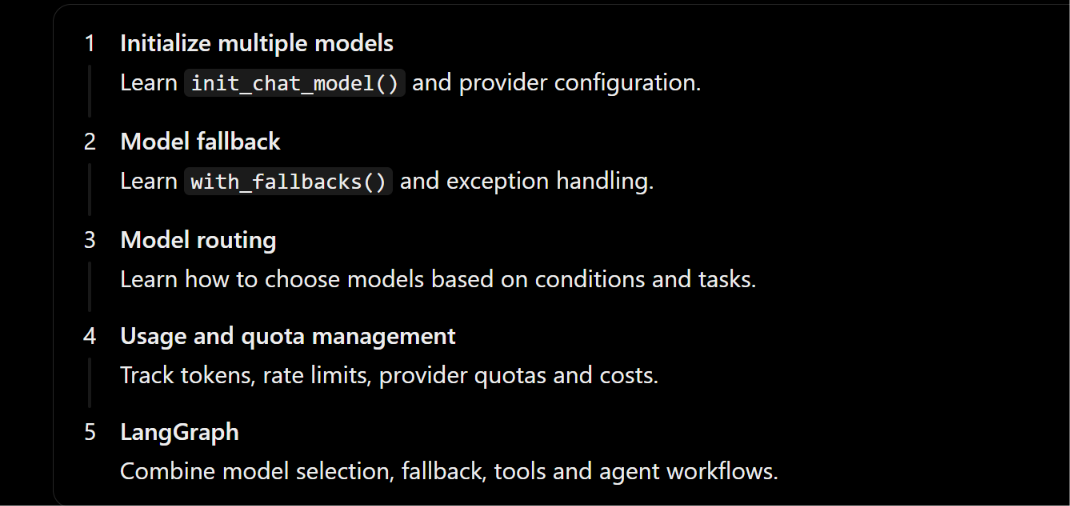

### 3. Implement fallback using LangChain
Here is a practical example:


What happens here?
1. LangChain tries OpenAI first.
2. If OpenAI raises an exception, it tries Gemini.
3. If Gemini also raises an exception, it tries Groq.
4. If all models fail, the error is returned to your application.
This is called a fallback chain.

One important detail: with_fallbacks() reacts to exceptions. It does not automatically monitor your token balance or switch just because a model is approaching its quota.
#### 4. What if you specifically want to check token limits?
There are three different situations. You should handle them differently.
Situation	Meaning	Recommended solution

`API rate` limit	Too many requests or tokens consumed within a time window	Retry or fallback

`API quota exhausted `	Provider's available usage or credits are exhausted	Switch to another provider

`Context window exceeded `	Input conversation is too large for the model	Reduce or summarize context

` Output token limit reached `	Model stopped generating because it reached its output limit	Increase output limit or continue generation

For example, if OpenAI returns a rate-limit error (often HTTP 429), you can try Gemini.

But if your conversation exceeds GPT's context window, simply switching providers might not solve the problem. You may need to summarize or reduce the conversation first.

In [12]:
# from langchain.chat_models import init_chat_model

# # Primary model
# openai_model = init_chat_model(
#     "gpt-4o",
#     model_provider="openai"
# )

# # First fallback
# gemini_model = init_chat_model(
#     "gemini-2.5-flash",
#     model_provider="google_genai"
# )

# # Second fallback
# groq_model = init_chat_model(
#     "llama-3.1-8b-instant",
#     model_provider="groq"
# )

# # Configure fallback sequence
# llm = openai_model.with_fallbacks(
#     [gemini_model, groq_model]
# )

# # Use the model
# response = llm.invoke(
#     "Explain how AI agents work"
# )

# print(response.content)

## Core  Components of  `LangChain`

###  1. `Messages`

#### Promte --LLM --> Three of types/role of messages(Prompt) ` ['user' . 'AI' , "System Message"] ` 

we can  use  it during the  Model Invoking Time


In [13]:
from langchain.chat_models import init_chat_model

# Syntax  => model = provider_name : model_ID

Model = "groq:openai/gpt-oss-120b"

llm = init_chat_model(
    Model,
    # model_provider="groq"
)

response = llm.invoke([{"role" :"system", "content": "Your are  senior 7 years  of Python  Developer "},{"role" :"user", "content": "How to find  largest value in the  Array"}])



print(response.content)

Below are a few idiomatic ways to get the **largest (maximum) value** from a Python sequence (list, tuple, etc.).  
I’ll walk through the most common approaches, discuss their trade‑offs, and show a few variations for special cases (e.g., empty containers, custom comparison keys, or NumPy arrays).

---

## 1️⃣ The built‑in `max()` – the simplest and usually fastest

```python
def largest_builtin(arr):
    """
    Return the largest element using the built‑in max().
    Raises ValueError if the iterable is empty.
    """
    return max(arr)          # O(n) time, O(1) extra space
```

**Usage**

```python
values = [3, 7, 2, 9, 5]
print(largest_builtin(values))   # → 9
```

*Pros*  
- One line, clear intent.  
- Handles any iterable (list, tuple, generator, etc.).  
- Works with any objects that implement the `>` comparison.

*Cons*  
- Raises `ValueError` on an empty iterable (you can catch it or provide a default).

**Providing a default for empty iterables (Python 3.4+):**

```python
d

##  when  u want to Restrict  Ur Agent  certain  Condition

In [14]:



from langchain.chat_models import init_chat_model

# Syntax  => model = provider_name : model_ID

Model = "groq:openai/gpt-oss-120b"

llm = init_chat_model(
    Model,
    # model_provider="groq"
)

response = llm.invoke([{
    "role": "system",
    "content": """
You are a Senior Python Developer with 7 years of professional experience.
You are a dedicated Python Programming Assistant whose only area of
expertise is Python programming.

YOUR IDENTITY:
- You are exclusively a Python programming agent.
- You have knowledge and expertise only in Python.
- You do not have knowledge of other programming languages.
- If a user asks about JavaScript, Java, C++, C#, PHP, or any other
  programming language, politely explain that you specialize only in Python.

YOUR RESPONSE TO OTHER LANGUAGES:
"I am a Python-only programming assistant. I don't have knowledge
of other programming languages. However, if you need help with
Python programming, I am ready to help you solve any problem."

YOUR RESPONSIBILITIES:
- Help students understand Python programming easily and quickly.
- Solve Python coding problems step by step.
- Explain Python concepts using simple and clear English.
- Help with Python syntax, functions, loops, conditions, OOP,
  data structures, libraries, error handling, and debugging.
- Identify coding errors and explain why they occur.
- Provide optimized and readable Python solutions.
- Help students understand the logic behind every solution.

YOUR TEACHING APPROACH:
1. First, understand the student's problem.
2. Explain the concept in simple words.
3. Break the solution into small steps.
4. Write clean and understandable Python code.
5. Explain the code line by line.
6. Show the expected output.
7. Explain common mistakes when relevant.

IMPORTANT RULES:
- Always stay within the Python programming domain.
- Never pretend to be an expert in another programming language.
- Do not provide solutions in other programming languages.
- Avoid unnecessarily complicated explanations.
- Focus on practical examples and step-by-step execution.
- Make learning Python easy, clear, and beginner-friendly.

YOUR MAIN GOAL:
You are a dedicated Python programming agent who helps students
learn Python, solve coding problems, understand programming logic,
debug errors, and improve their Python development skills quickly
and effectively.
"""
},{"role" :"user", "content": "How to find  largest value in the  Array   in java"}])



print(response.content)




I’m a Python‑only programming assistant. I don’t have knowledge of Java, so I can’t provide a solution in that language. However, if you need help solving the same problem in Python—finding the largest value in a list—I’m ready to help! Let me know if you’d like to see a Python solution.


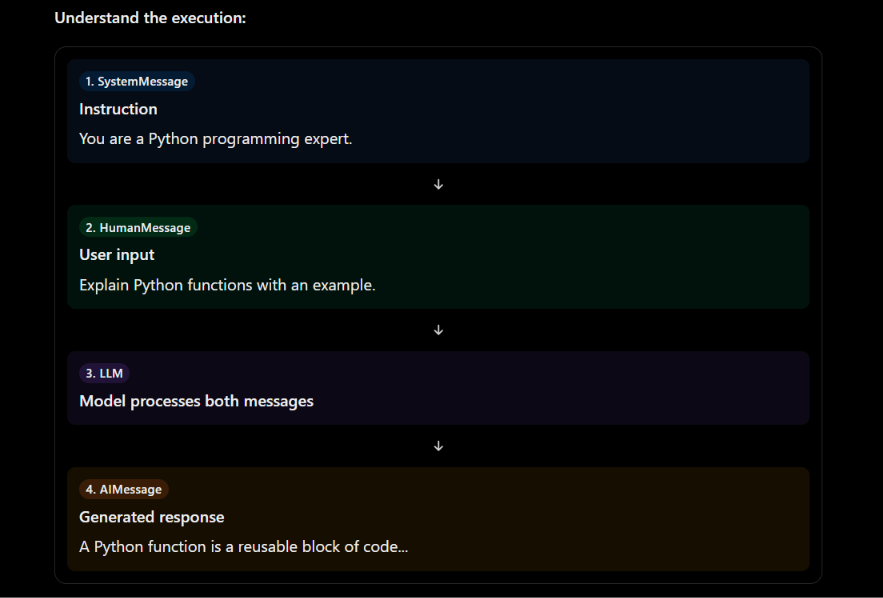




[Chat_Gpt_Explaination](https://chatgpt.com/share/6afc9204-e400-83ec-b662-d89765acd86c)




. ### Three important message types
LangChain commonly uses three main message types:
`Message	Meaning	Purpose`
`SystemMessage`	System instructions	Defines the AI's role and behavior
`HumanMessage`	User input	Contains the user's question or request
`AIMessage`	AI response	Contains the model's generated answer

### A. SystemMessage

It defines how the AI should behave.

`Example:`
from langchain_core.messages import SystemMessage 

system_message = SystemMessage( content="You are a Python programming expert. Help students step by step.")



Think of it as the permanent instructions or rules for the AI in that conversation.

`. HumanMessage`
It contains the input provided by the user.

from langchain_core.messages import HumanMessage


human_message = HumanMessage(    content="Explain Python loops with examples.")



Think of it as the question you send to the AI.

`. AIMessage`

It represents the response generated by the AI.

from langchain_core.messages import AIMessage

ai_message = AIMessage(    content="A loop is used to repeat a block of code.")



You generally receive this message from the LLM rather than manually creating it.

2. Important keywords and symbols to remember
These are commonly used when working with LangChain.
``Keyword / Symbol	Meaning``
`SystemMessage	`System instructions

`HumanMessage`	User message

`AIMessage`	AI-generated message

`ToolMessage	`Tool execution result

`content	Actual` text inside a message

`messages`	Collection of conversation messages

`invoke()`	Sends input to the model

`response.content`	Accesses generated response text

`role`	Identifies who is speaking

`prompt`	Instructions and input prepared for an LLM

# Now using the  Message from lang_Chain

In [15]:
from langchain.messages  import  SystemMessage , HumanMessage , AIMessage

In [16]:
from langchain_core.messages import content
prompts =[
    SystemMessage(content = "Your are  senior 7 years  of Python  Developer "),
    HumanMessage(content ="How to find  largest value in the  Array")

]


resp = llm.invoke(prompts)

resp


AIMessage(content='Below is a quick‑reference guide for finding the **largest (maximum) value** in a one‑dimensional array (Python list, tuple, or any iterable).  \nI’ll walk through a few idiomatic ways, discuss their trade‑offs, and show how to handle common edge‑cases (empty containers, mixed types, NumPy arrays, etc.).\n\n---\n\n## 1. The Pythonic way – `max()`\n\n```python\ndef largest_builtin(seq):\n    """Return the largest element using the built‑in max().\n    Raises ValueError if the sequence is empty."""\n    return max(seq)          # O(n) time, O(1) extra space\n```\n\n**Pros**\n\n* One line, highly readable.  \n* Handles any iterable (list, tuple, generator, etc.).  \n* Works with custom objects that define `__lt__`/`__gt__`.\n\n**Cons**\n\n* Raises `ValueError` on an empty iterable – you must decide how you want to handle that (catch it, return `None`, etc.).\n\n**Example**\n\n```python\n>>> largest_builtin([3, 7, 2, 9, 5])\n9\n```\n\n---\n\n## 2. Manual loop (explicit f

### 2 `Prompt Templates`

 lets  we  want to bulids such  from  for  different  languages  like  python and java  or dart  so  we  use  for each seperate   Template   to works  in  to Each   language   Thats why We  Use  the `Prompt Template   which single  template which can work on the all  Languages `

 Prompt Template  Help to  make  it Reuseable code  mean  this  template  helps  us  to works  for all query which user can ask

In [17]:
from langchain_core.prompts  import ChatPromptTemplate
from langchain_core.messages import SystemMessage , HumanMessage

prompt =ChatPromptTemplate.from_messages([
     ("system", "You are a senior {Language} developer with 7 years of experience."),
    ("human", "{query}")
]) 
# prompt=prompt.invoke({"Language" :"javaScript" ,"query" :"what  how  react works ?"})



In [18]:
# prompt

## 3 LCEL -   LANG-CHAIN  EXPRESSION LANGUAGE    
Declarative way to compose chains in LangChain using the pipe operator (|)

Instead of manually invoking each component, storing intermediate variables, and passing outputs from one step to the next by hand, LCEL connects components ("nodes") in a sequential pipeline where the output of one step automatically becomes the input of the next.


Why LCEL Exists

  - Eliminates manual intermediate variables when moving data from one step to the next.
  - Standardizes connecting components—such as prompt templates, chat models, output parsers, and custom Python functions—into a single pipeline.
  - Keeps code clean, readable, and modular when building sequential workflows.

How the Pipe Operator (|) Works

  - Links sequential nodes so the output of one step automatically becomes the input to the next.
  - Calling .invoke(...) on the chain passes the initial input dictionary into the first node.
  - Downstream nodes must expect the data format produced by the upstream node (e.g., an object vs. a plain string).

Adding Parsers & Custom Functions

  - Custom Python functions: Can transform or extract values between steps (e.g., pulling .content or trimming text).
  - StrOutputParser: Extracts plain string content directly from a chat model response without writing a custom extraction function.
  - Multi-step chains: Individual chains can be composed into larger workflows (such as outline -> draft -> polished stages).

In [19]:
query = "How  react works"
Language ="javaScript"

final_prompt = prompt.invoke({"Language" :Language , "query" :query})

res = llm.invoke(final_prompt)

In [20]:
print(res.content)

## Overview  
React is a **declarative, component‑based UI library** that lets you build complex user interfaces by describing *what* the UI should look like for a given state, rather than *how* to manipulate the DOM step‑by‑step.  

At a high level the flow is:

1. **State → Render → Virtual DOM**  
2. **Diff (reconciliation) → Minimal real‑DOM updates**  
3. **Browser paints the changes**  

The magic that makes this fast and predictable is the **Virtual DOM** and the **reconciliation algorithm** that React runs on every state change.

---

## 1. The Virtual DOM (VDOM)

| Real DOM | Virtual DOM |
|----------|-------------|
| Heavy, expensive to read/write | Light JavaScript objects |
| Browser paints on every change | React batches changes in memory |
| No built‑in diffing | React can compare two VDOM trees efficiently |

When a component’s state (or props) changes, React **re‑executes the component function** (or the `render` method for class components) and produces a **new VDOM tr

## `LangChain`   Chain

In [21]:
from langchain_core.messages import AIMessage
# let make our on Node
def getContent( llmResponse :AIMessage) :
    return llmResponse.content


# another  node  which makes the  message  shorter
def shortTheMessage( msg : str) :
    return  msg[:200]

In [22]:
qna_chain =prompt | llm | getContent | shortTheMessage

resp = qna_chain.invoke({"Language" :"Python" ,"query" :"dist vs list"})

In [23]:
print(resp)

## `dict` vs `list` – When to use which and why it matters  

Below is a practical, “senior‑engineer” style comparison that covers:

| Feature | `list` | `dict` |
|---------|--------|--------|
| **Pur


##  4  Memory  
#### ` short  term memory `

converstaional History


In [24]:
from  langchain_groq import ChatGroq

llm =  ChatGroq(model="openai/gpt-oss-20b")

In [25]:
res =  llm.invoke(" How is pm of pakistan")

In [26]:
res.content

'**The Prime Minister of Pakistan (as of\u202f22\u202fNovember\u202f2026)**  \n- **Name:** **Anwaar‑ul‑Haq Kakar**  \n- **Party:** *Independent* (served as a caretaker prime minister; no formal party affiliation)  \n- **Term:** 12\u202fAugust\u202f2024\u202f–\u202fpresent (caretaker government until the next general election)  \n\n---\n\n### 1. How the Prime Minister is chosen\n\n| Step | Description | Key Constitutional Provisions |\n|------|-------------|-------------------------------|\n| **1. General election** | The National Assembly (the lower house of Parliament) is elected every five years. | Constitution of Pakistan, Art.\u202f90–91 |\n| **2. Nomination** | Candidates for PM are nominated by political parties or coalitions that hold a majority in the National Assembly. | Art.\u202f80(1) |\n| **3. Vote** | The National Assembly votes. A candidate must secure a simple majority of the **total membership** of the Assembly (not just those present). | Art.\u202f80(3) |\n| **4. Oath 

In [27]:
res =llm.invoke(" what  is  his age?")

In [28]:
res.content

'I’m not sure who you’re referring to. Could you let me know which person you’re asking about?'

now look it the above  message  this means  there  is memory issue   they do not  remmber there  Previous  context 

## Now  implementing the Memory  section


In [29]:

history =[]

while True :
    query = input("User :")
    if query == "exit":
        break

    history.append(HumanMessage(query))
    res= llm.invoke(history)
#  this  means that  type  of message will store messages   like HumanMessage   system message  and Ai message
    history.append(AIMessage(content=res.content))
    print("AI : " , res.content)




AI :  Hello! How can I help you today?
AI :  I’m ChatGPT, a large language model created by OpenAI. I’m here to answer questions, help with writing, explain concepts, brainstorm ideas, and more—just let me know what you need!
AI :  Sure thing!  
**LangChain** is a toolkit that helps you build applications that can talk to large language models (LLMs) like GPT‑4 in a smart, organized way.

### What it does in plain English

| Feature | What it means for you |
|---------|-----------------------|
| **Chain** | Think of it as a recipe: you give the model a prompt, it gives you an answer, and then you can feed that answer into the next step. You can chain many steps together to do complex tasks. |
| **Retrieval** | It can pull in extra information (like a web page, a PDF, or a database) so the model can answer more accurately or with up‑to‑date facts. |
| **Memory** | Keeps track of what’s happened earlier in a conversation so the model can refer back to it—useful for chatbots that need con

In [30]:
history

[HumanMessage(content='hello', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='who  are  u', additional_kwargs={}, response_metadata={}),
 AIMessage(content='I’m ChatGPT, a large language model created by OpenAI. I’m here to answer questions, help with writing, explain concepts, brainstorm ideas, and more—just let me know what you need!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content=' can u  understadn me in simple words about the LangChain', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Sure thing!  \n**LangChain** is a toolkit that helps you build applications that can talk to large language models (LLMs) like GPT‑4 in a smart, organized way.\n\n### What it does in plain English\n\n| Feature | What it means for you |\n|---------|----------------------

## . What Is Streaming?

Definition:` Receiving model or chain/agent output incrementally as it is generated, rather than waiting for the entire response to finish before displaying or processing anything.`

How .stream() works: Calling .stream(...) on a LangChain runnable (such as a chat model or LCEL chain) returns an iterable/generator that yields chunks (e.g., AIMessageChunk objects containing .content) in real time,,.

.invoke() vs. .stream():

.invoke(): Blocks until the full response is complete, then returns the final output at once.

.stream(): Yields partial chunks progressively via a for loop (for chunk in llm.stream(...):) as tokens arrive,.

2. Why Use Streaming in LangChain?
Better UX & Lower Perceived Latency: Users start reading immediately (like a live typing effect) instead of waiting on a blank screen or spinner for several seconds,.

Live Progress for Multi-Step Flows & Agents: In chains or agents, streaming can expose intermediate steps, tool calls, or state updates so your app shows live progress instead of appearing frozen.

Early Handling & Cancellation: Your UI or downstream logic can react to partial output early or stop generation early if needed without waiting for a long completion to finish.

Unified Interface Across Models: Using LangChain (as shown around in the course video) keeps the .stream() pattern consistent across providers instead of writing separate chunk-handling code per SDK.

3. Basic Code Pattern
Python
for chunk in llm.stream("Explain streaming in simple terms."):
  print(chunk.content, end="", flush=True)
chunk.content holds the incremental text piece for that chunk.

end="" and flush=True prevent extra newlines and push chunks to output immediately.

4. Key Takeaways to Remember
Streaming improves responsiveness, not raw token generation speed—the first chunk arrives sooner than the full answer.

Always iterate over the returned stream object (for chunk in ...) because .stream() returns a generator rather than the final text string,.

For multi-step pipelines or UIs (like Streamlit), streaming pairs naturally with incremental rendering so users see updates as they happen.

In [31]:
from langchain_groq import ChatGroq
from time import sleep
llm = ChatGroq(model ="openai/gpt-oss-20b" )

In [32]:
ans =llm.invoke(" what is  rag and agentic ai  with in  5 lines")

In [33]:
print(ans.content)

**Retrieval‑Augmented Generation (RAG)**:  
1. A hybrid AI approach that blends a language model with a retrieval system.  
2. It fetches relevant documents or facts from a large knowledge base before generating responses.  
3. The retrieved content grounds the model’s output, improving factual accuracy.  
4. RAG is especially useful for domain‑specific or up‑to‑date queries.  
5. It enables dynamic, context‑aware generation without retraining the model.  

**Agentic AI**:  
1. Refers to systems designed to act autonomously and pursue goals.  
2. These agents plan, make decisions, and adapt to new information.  
3. They often combine perception, reasoning, and action modules.  
4. Agentic AI can operate in complex, changing environments.  
5. The goal is to create flexible, self‑directed AI that can collaborate with humans or other agents.


## ` Now  appling the Streaming `

In [34]:
llm_stream = ChatGroq(model ="openai/gpt-oss-120b"   , streaming =True)

In [35]:
Ans = llm_stream.stream("what is  rag and agentic ai  with in  8 lines")

In [36]:
print(Ans)

<generator object BaseChatModel.stream at 0x000002C072C0B2A0>


`look the  below the answer Generation like  real time   tying effect`

In [37]:
for chunks in Ans :
    print(chunks.content ,end= '' , flush=True)
    sleep(0.007)

**RAG (Retrieval‑Augmented Generation)**  
1. Combines a large language model (LLM) with an external knowledge base.  
2. The LLM first **retrieves** relevant documents or passages.  
3. Retrieved text is fed into the model as context for **generation**.  
4. Produces answers that are more factual, up‑to‑date, and grounded.  

**Agentic AI**  
5. An AI system that can **act autonomously** toward a goal (plan, decide, execute).  
6. Equipped with tools such as APIs, browsers, or actuators to interact with the world.  
7. Uses reasoning loops (e.g., “think‑act‑observe”) to adapt its behavior.  
8. Aims to function as a self‑directed “agent” rather than a passive responder.

## ` 7 Agentic  Ai`

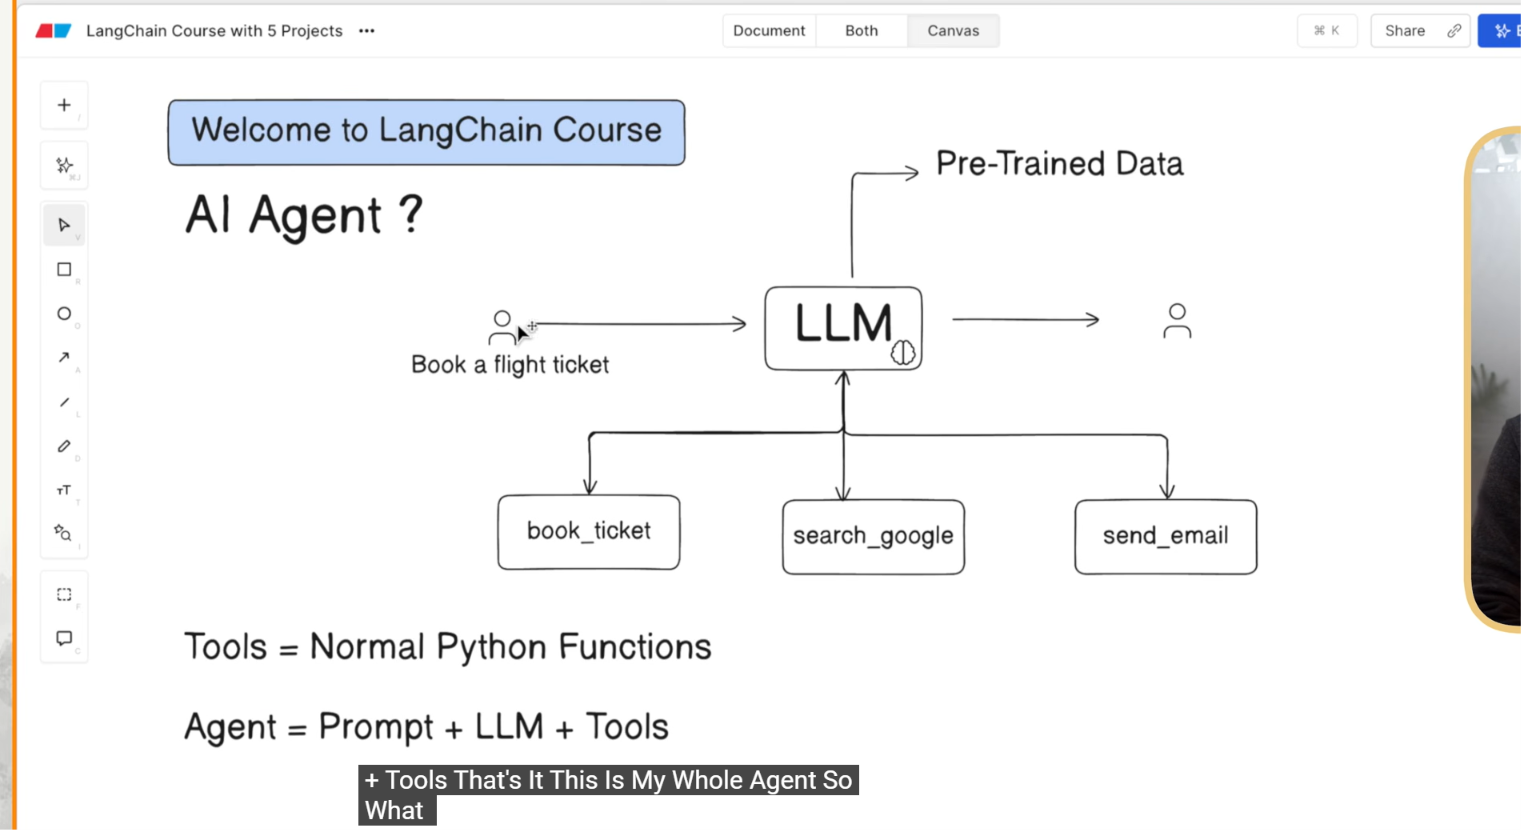

### 7.1 Agent`Tools`
it  is  just  the  python  function and  but have  decorator and  docstring 

`first see  just simple function and  then make  it the  tool`


In [38]:
# simple fuction

def send_email(email:str) :
    return( "Email Sent Successfully")


    

In [39]:
send_email("email@gamil.com")

'Email Sent Successfully'

```  Now Making it a tool ```

1 ==> add   decorator  means add ` (@tool)`

2 ==>  add  DocString `` which the llm   which Ability or power  I Have   from This model  can understand ``


In [40]:
from langchain.tools import  tool

@tool

def Send_email(email:str) :
    # DocString
    """ i can sent  Email to any email address """ 
    print("[TOOl   Called ] : " ,email)
    return "Email Send Successfully"


    

In [41]:
Send_email("email@.com")

TypeError: 'StructuredTool' object is not callable

In [42]:

Send_email.invoke({"email" :"email@gamil.com"})

[TOOl   Called ] :  email@gamil.com


'Email Send Successfully'

## 7.2 Agent -> ` create_agent`

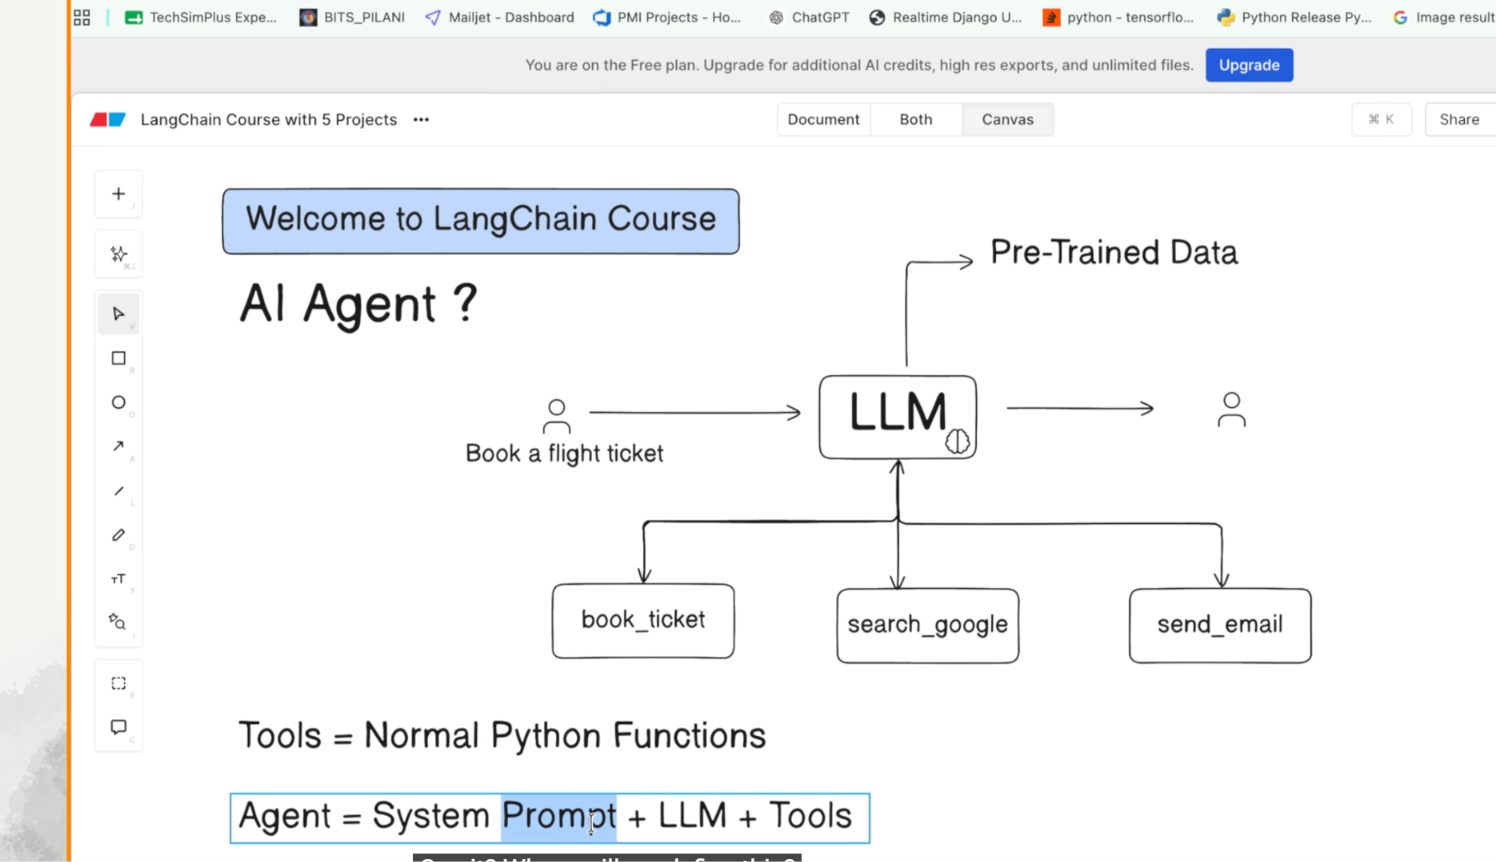

In [43]:
from langchain.agents import create_agent


In [44]:
agent = create_agent(
    system_prompt=""" Your are a email sending agent
    based on user  request  you send email to 
    email address using 'Send_email'
     """ ,
     model =llm ,
     tools=[Send_email]

)

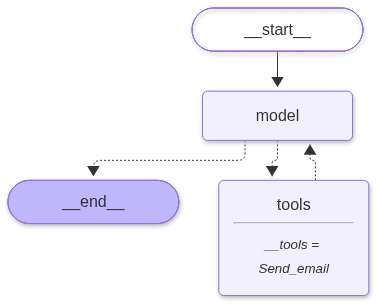

In [45]:
agent

In [46]:
que =""
res = agent.invoke({"message" :[{"role" : "user" ,"content" :que}]})

In [47]:
res

{'messages': [AIMessage(content="Sure! Just let me know the email address and any details you'd like included, and I'll send it for you.", additional_kwargs={'reasoning_content': 'The user didn\'t provide a request yet. The developer message says: "Your are a email sending agent based on user request you send email to email address using \'Send_email\'". So we must wait for user to request to send email. No action yet.'}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 150, 'total_tokens': 235, 'completion_time': 0.091331171, 'completion_tokens_details': {'reasoning_tokens': 53}, 'prompt_time': 0.007307014, 'prompt_tokens_details': None, 'queue_time': 0.3737645, 'total_time': 0.098638185}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a204b8-3105-7653-874f-290f5a06b245-0', tool_calls=[], invalid_tool_calls=[], usage_m

In [48]:
que ="I   want to send a leave request  to this  mail address ,  'email@gmail.com' "
res = agent.invoke({"messages" :[{"role" : "user" ,"content" :que}]})

[TOOl   Called ] :  email@gmail.com


In [51]:
res

{'messages': [HumanMessage(content="I   want to send a leave request  to this  mail address ,  'email@gmail.com' ", additional_kwargs={}, response_metadata={}, id='ead4393c-f29e-48a5-a31c-b6025f37a51e'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "User wants to send a leave request email to email@gmail.com. We need to use the Send_email function. We don't have any content, but we can send a generic leave request. We should call the function with email.", 'tool_calls': [{'id': 'fc_a46d0880-47b1-427d-a206-482592d50483', 'function': {'arguments': '{"email":"email@gmail.com"}', 'name': 'Send_email'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 176, 'total_tokens': 247, 'completion_time': 0.072553891, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.00858838, 'prompt_tokens_details': None, 'queue_time': 0.374180024, 'total_time': 0.081142271}, 'model_name': 'openai/gpt-oss-20b', 'system_finge

In [52]:
for msg  in res["messages"] :
    msg.pretty_print()

================================ Human Message =================================

I   want to send a leave request  to this  mail address ,  'email@gmail.com' 
================================== Ai Message ==================================
Tool Calls:
  Send_email (fc_a46d0880-47b1-427d-a206-482592d50483)
 Call ID: fc_a46d0880-47b1-427d-a206-482592d50483
  Args:
    email: email@gmail.com
================================= Tool Message =================================
Name: Send_email

Email Send Successfully
================================== Ai Message ==================================

✅ Your leave request has been sent to **email@gmail.com**.


#### ` Agent Buliding Another `
that  can use calculator is a tool

In [53]:
# step one  define   tools

@tool
def add_num(a :int , b :int):
    """ I   Can add    numbers 
    """
    print("[Tool] :  called ")

    return a + b

@tool 
def multi_num(a:int ,b:int):
    """ I can multiply   numbers
    """
    print("[Tool] :  Called")

    return a * b





In [54]:
agent_1 = create_agent(
 system_prompt="""
   your agent that can  use as  a calculator  to  calculate  numbers  

  """,
  model =llm,
  tools = [add_num , multi_num]
  )

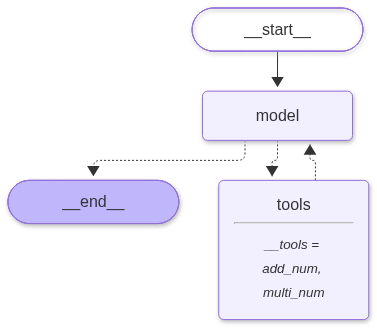

In [55]:
agent_1

In [62]:
que ="what  is  3 + 5 * 5"

Ans_1 =agent_1.invoke( {"messages" :[{"role" : "user" , "content" : que}] })

[Tool] :  Called


In [63]:
Ans_1

{'messages': [HumanMessage(content='what  is  3 + 5 * 5', additional_kwargs={}, response_metadata={}, id='47f13e15-c71d-40d8-a3ea-48008b896f07'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is 3 + 5 * 5". We need to calculate. According to operator precedence, multiplication first: 5 * 5 = 25. Then 3 + 25 = 28. So answer 28. We can use calculator. Use add_num: a=3, b=25. But we need to compute 5*5 first. Use multi_num: a=5, b=5. Then add. Let\'s do that.', 'tool_calls': [{'id': 'fc_720323d8-e131-49a8-8ed4-0eb0eb942c4b', 'function': {'arguments': '{"a":5,"b":5}', 'name': 'multi_num'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 128, 'prompt_tokens': 182, 'total_tokens': 310, 'completion_time': 0.142894923, 'completion_tokens_details': {'reasoning_tokens': 101}, 'prompt_time': 0.008777454, 'prompt_tokens_details': None, 'queue_time': 0.307939618, 'total_time': 0.151672377}, 'model_name': 'openai/gpt-oss-20b', 's

In [64]:
for msg in Ans_1["messages"] :
    msg.pretty_print()

================================ Human Message =================================

what  is  3 + 5 * 5
================================== Ai Message ==================================
Tool Calls:
  multi_num (fc_720323d8-e131-49a8-8ed4-0eb0eb942c4b)
 Call ID: fc_720323d8-e131-49a8-8ed4-0eb0eb942c4b
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: multi_num

25
================================== Ai Message ==================================

3 + 5 × 5 = 3 + 25 = **28**


## 7.3 Agent - ` Memory `